# IT Incident Prioritization — Fuzzy Control System

**Fuzzy Sets and Systems | Programming tutorial — individual application**

This notebook applies the **fuzzy control approach from Notebook 01** to an idea from our group project: *Human-Centred Fuzzy Decision Support for IT Incident Prioritization*.

An IT support team may have to compare incidents that differ in urgency and in the importance of the affected service. Rather than using rigid thresholds, we build a simple rule-based model with:

- **Inputs:** incident urgency and service importance, each scored from **0 to 10**.
- **Output:** a recommended priority score from **0 to 100**, described as *Low*, *Medium*, *High*, or *Critical*.

This is a **small illustrative prototype**, not a fully operational incident-management system. The scores, membership functions, and rules are assumptions made for this tutorial.

## 1. Define the fuzzy variables

We use `scikit-fuzzy` in the same way as the first tutorial: `Antecedent` for inputs and `Consequent` for the output. The fuzzy sets overlap, so an input can partially belong to more than one linguistic category.

For simplicity, both inputs have the same three membership functions: **Low**, **Medium**, and **High**. The output has four: **Low**, **Medium**, **High**, and **Critical**.

c:\Users\aqual\Desktop\M\FSS\fuzzy-tutorial\.venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


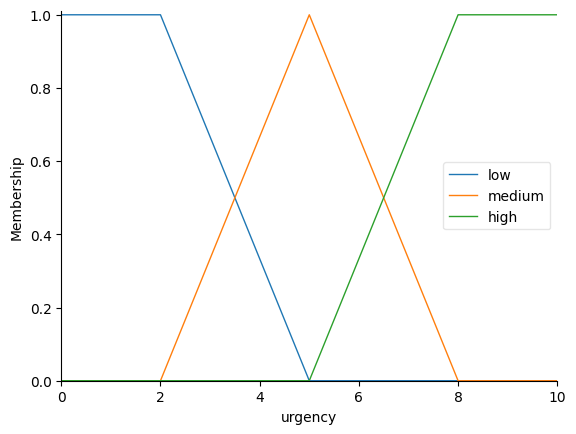

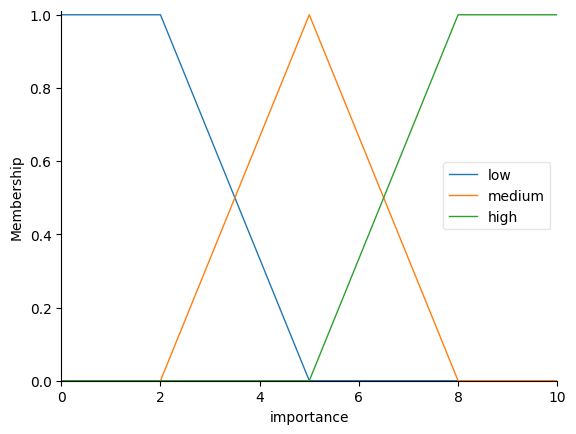

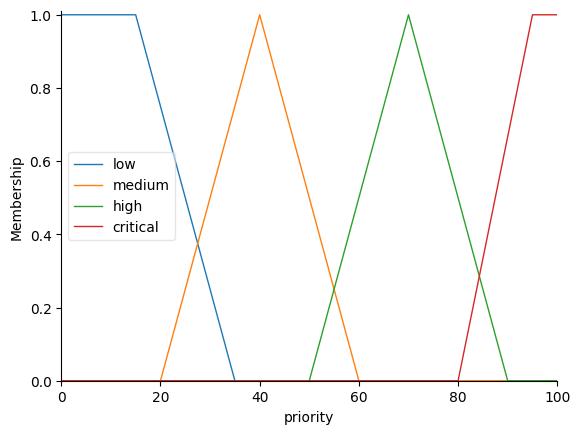

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Two inputs (0-10) and one output (0-100)
urgency = ctrl.Antecedent(np.arange(0, 10.1, 0.1), 'urgency')
importance = ctrl.Antecedent(np.arange(0, 10.1, 0.1), 'importance')
priority = ctrl.Consequent(np.arange(0, 100.1, 0.1), 'priority')

# Input membership functions: low / medium / high
for variable in (urgency, importance):
    variable['low'] = fuzz.trapmf(variable.universe, [0, 0, 2, 5])
    variable['medium'] = fuzz.trimf(variable.universe, [2, 5, 8])
    variable['high'] = fuzz.trapmf(variable.universe, [5, 8, 10, 10])

# Output membership functions: low / medium / high / critical
priority['low'] = fuzz.trapmf(priority.universe, [0, 0, 15, 35])
priority['medium'] = fuzz.trimf(priority.universe, [20, 40, 60])
priority['high'] = fuzz.trimf(priority.universe, [50, 70, 90])
priority['critical'] = fuzz.trapmf(priority.universe, [80, 95, 100, 100])

urgency.view()
importance.view()
priority.view()

## 2. Define the IF–THEN rules

Following Notebook 01, we use **Mamdani-style fuzzy rules**. Each of the three urgency levels is combined with each of the three service-importance levels, for **nine rules**.

| Urgency ↓ / Importance → | Low | Medium | High |
|:--|:--|:--|:--|
| **Low** | Low | Low | Medium |
| **Medium** | Medium | Medium | High |
| **High** | High | High | Critical |

For example, a high-urgency issue affecting a highly important service is assigned the **Critical** fuzzy output.

In [16]:
rule1 = ctrl.Rule(urgency['low'] & importance['low'], priority['low'])
rule2 = ctrl.Rule(urgency['low'] & importance['medium'], priority['low'])
rule3 = ctrl.Rule(urgency['low'] & importance['high'], priority['medium'])

rule4 = ctrl.Rule(urgency['medium'] & importance['low'], priority['medium'])
rule5 = ctrl.Rule(urgency['medium'] & importance['medium'], priority['medium'])
rule6 = ctrl.Rule(urgency['medium'] & importance['high'], priority['high'])

rule7 = ctrl.Rule(urgency['high'] & importance['low'], priority['high'])
rule8 = ctrl.Rule(urgency['high'] & importance['medium'], priority['high'])
rule9 = ctrl.Rule(urgency['high'] & importance['high'], priority['critical'])

incident_control = ctrl.ControlSystem([
    rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9
])
print('Fuzzy control system created successfully.')

Fuzzy control system created successfully.


## 3. Try one incident

Consider a fairly urgent issue (**7/10**) affecting an important service (**8.5/10**). We provide these values to a `ControlSystemSimulation`, compute the result, and visualize the activated output.

By default, the controller uses **centroid defuzzification** to obtain a single priority score.

Recommended priority score: 80.22 / 100


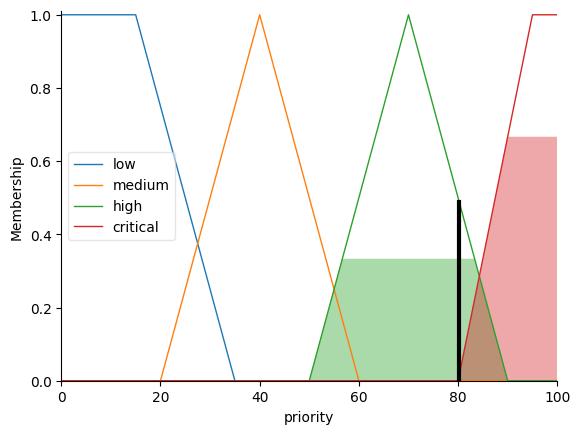

In [17]:
simulation = ctrl.ControlSystemSimulation(incident_control)
simulation.input['urgency'] = 7.0
simulation.input['importance'] = 8.5
simulation.compute()

print(f"Recommended priority score: {simulation.output['priority']:.2f} / 100")
priority.view(sim=simulation)

## 4. Compare a few example incidents

Let's run the same system on several hypothetical IT incidents. As in Notebook 01, every recommendation comes from the same membership functions and rules; only the inputs change.

To display a readable priority category alongside each score, we select the output fuzzy set with the **highest membership at the defuzzified score**. This label is for presentation; it is not a separate inference step.

Minor visual glitch               ->  13.2/100 (Low)
Internal reporting issue          ->  47.3/100 (Medium)
Core service degradation          ->  74.6/100 (High)
Urgent nonessential component     ->  70.0/100 (High)
Authentication unavailable        ->  93.0/100 (Critical)


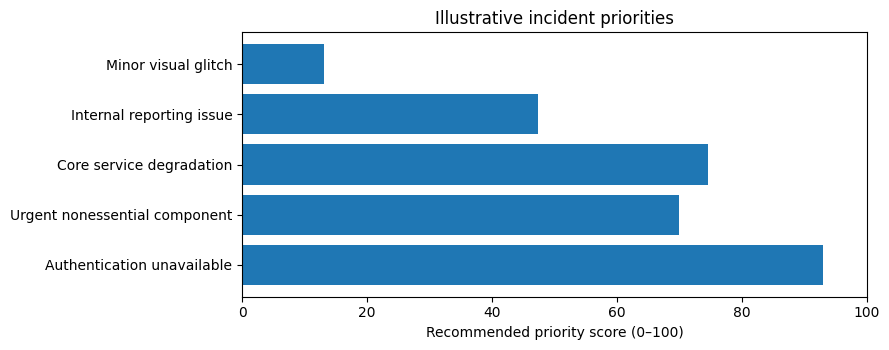

In [ ]:
incidents = [
    ('Minor visual glitch', 1.0, 1.0),
    ('Internal reporting issue', 5.5, 4.0),
    ('Core service degradation', 6.0, 9.0),
    ('Urgent nonessential component', 9.0, 2.0),
    ('Authentication unavailable', 9.5, 9.5),
]

results = []
for name, incident_urgency, service_importance in incidents:
    test = ctrl.ControlSystemSimulation(incident_control)
    test.input['urgency'] = incident_urgency
    test.input['importance'] = service_importance
    test.compute()
    score = float(test.output['priority'])

    # Find the output category with the highest membership at this score
    memberships = {
        term: fuzz.interp_membership(priority.universe, priority[term].mf, score)
        for term in ('low', 'medium', 'high', 'critical')
    }
    label = max(memberships, key=memberships.get)
    results.append((name, score, label))
    print(f'{name:33s} -> {score:5.1f}/100 ({label.capitalize()})')

# Simple visualization of the recommendations
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh([row[0] for row in results], [row[1] for row in results])
ax.set(xlim=(0, 100), xlabel='Recommended priority score (0-100)',
       title='Illustrative incident priorities')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 5. Discussion

The example shows how **fuzzy sets and IF–THEN rules** turn two imprecise assessments into a numerical recommendation. An incident can activate several rules at once; the controller combines their output sets before defuzzifying them.

**Limitations:** This first prototype uses only urgency and service importance. It does not yet account for the number of affected users, operational impact, or relationships between incidents, which will be 
implemented in the final project.

Author: Alec Imhof